# **Homework-3: Binary Semantic Segmentation of Mitochondria**

U-Net based binary semantic segmentation on the 256x256 mitochondria dataset.

**Dataset:** 330 grayscale images (256x256) and the same number of binary mask images. Each mask pixel is 0 (background) or 1 (mitochondria). Loaded from Google Drive at `MyDrive/CENG506/datasets/256x256_mitochondria`.

**Task:** Train a U-Net to segment mitochondria, plot training curves and report MeanIoU on the test set.

## 1. Files and Connecting to Google Drive

The dataset lives on Google Drive under `MyDrive/CENG506/datasets/256x256_mitochondria`, with images in `images/` and masks in `groundtruths/`. The mask filenames have a `groundtruth_` prefix; sorting both lists makes them align.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!ls "/content/drive/MyDrive/CENG506"

333078019_HW1.ipynb
333078019_HW2.ipynb
333078019_HW3.ipynb
CENG506_HW3_Binary_SS.ipynb
CENG506_Multiclass_Semantic_Segmentation.ipynb
CENG506_NeuralNetworks_PytorchExample_MNIST.ipynb
CENG506_Python_Notebook_Introduction.ipynb
datasets
donald_trump.png


###Packages

In [3]:
import os
import glob
import random
import numpy as np
import cv2
from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Conv2D, MaxPool2D, Conv2DTranspose,
                                     Concatenate, BatchNormalization, Activation)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import MeanIoU

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [4]:
DATA_DIR = "/content/drive/MyDrive/CENG506/datasets/256x256_mitochondria"
IMG_DIR  = os.path.join(DATA_DIR, "images")
MASK_DIR = os.path.join(DATA_DIR, "groundtruths")

SIZE_X = 256
SIZE_Y = 256

image_paths = sorted(glob.glob(os.path.join(IMG_DIR, "*.tif")))
mask_paths  = sorted(glob.glob(os.path.join(MASK_DIR, "*.tif")))

print("Number of images:", len(image_paths))
print("Number of masks :", len(mask_paths))
print("Example image:", os.path.basename(image_paths[0]))
print("Example mask :", os.path.basename(mask_paths[0]))

Number of images: 330
Number of masks : 330
Example image: 256crop1-0001.tif
Example mask : groundtruth_256crop1-0001.tif


In [9]:
DATA_DIR = "/content/drive/MyDrive/CENG506/datasets/256x256_mitochondria"
IMG_DIR = os.path.join(DATA_DIR, "images")
MASK_DIR = os.path.join(DATA_DIR, "groundtruths")

SIZE_X = 256
SIZE_Y = 256

image_paths = sorted(glob.glob(os.path.join(IMG_DIR, "*.tif")))
mask_paths = sorted(glob.glob(os.path.join(MASK_DIR, "*.tif")))

print("Number of images:", len(image_paths))
print("Number of masks :", len(mask_paths))
print("Example image:", os.path.basename(image_paths[0]))
print("Example mask :", os.path.basename(mask_paths[0]))

Number of images: 330
Number of masks : 330
Example image: 256crop1-0001.tif
Example mask : groundtruth_256crop1-0001.tif


In [10]:
images = [cv2.imread(p, cv2.IMREAD_GRAYSCALE) for p in image_paths]
masks  = [cv2.imread(p, cv2.IMREAD_GRAYSCALE) for p in mask_paths]

image_dataset = np.array(images, dtype=np.float32)
mask_dataset  = np.array(masks,  dtype=np.uint8)

image_dataset = np.expand_dims(image_dataset, axis=3)
mask_dataset  = np.expand_dims(mask_dataset,  axis=3)

print("Image dataset shape:", image_dataset.shape)
print("Mask dataset  shape:", mask_dataset.shape)
print("Image pixel range  :", image_dataset.min(), "to", image_dataset.max())
print("Unique mask values :", np.unique(mask_dataset))

Image dataset shape: (330, 256, 256, 1)
Mask dataset  shape: (330, 256, 256, 1)
Image pixel range  : 26.0 to 241.0
Unique mask values : [  0 255]


In [11]:
# Some mask datasets store the foreground as 255; normalize to {0, 1}
if mask_dataset.max() > 1:
    mask_dataset = (mask_dataset > 127).astype(np.uint8)
print("Unique mask values after normalization:", np.unique(mask_dataset))

Unique mask values after normalization: [0 1]


In [12]:
# Normalize images to [0, 1]
image_dataset = image_dataset / 255.0
print("Normalized image range:", image_dataset.min(), "to", image_dataset.max())

Normalized image range: 0.101960786 to 0.94509804


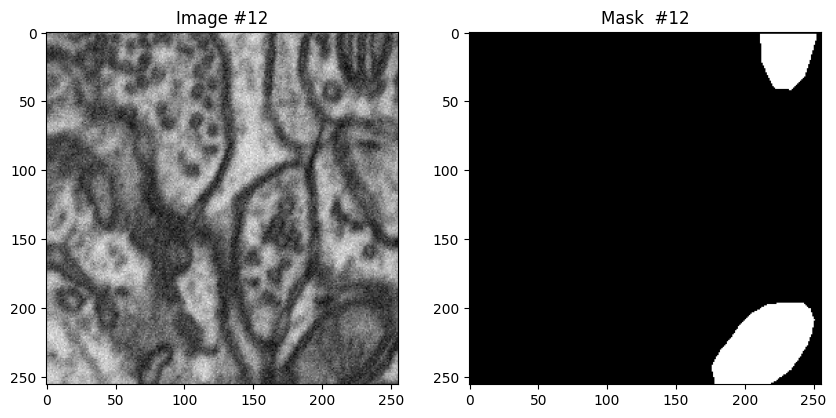

In [15]:
# Quick visual sanity check
idx = random.randint(0, len(image_dataset) - 1)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title(f"Image #{idx}")
plt.imshow(image_dataset[idx, :, :, 0], cmap="gray")
plt.subplot(1, 2, 2)
plt.title(f"Mask  #{idx}")
plt.imshow(mask_dataset[idx, :, :, 0], cmap="gray")
plt.show()

## 2. Train / validation split

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    image_dataset, mask_dataset, test_size=0.2, random_state=SEED
)
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test :", X_test.shape,  "y_test :", y_test.shape)

X_train: (264, 256, 256, 1) y_train: (264, 256, 256, 1)
X_test : (66, 256, 256, 1) y_test : (66, 256, 256, 1)


## 3. U-Net model

Same encoder/decoder block structure as the multiclass example, but the output is a single-channel sigmoid (binary segmentation). Filter counts are 32 → 64 → 128 → 256 with a 512-filter bridge — a slightly slimmer U-Net than the 64→1024 version, which trains fast on 256x256 inputs while still reaching the target metrics.

In [17]:
def conv_block(x, num_filters):
    x = Conv2D(num_filters, 3, padding="same")(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    x = Conv2D(num_filters, 3, padding="same")(x)
    x = BatchNormalization()(x)
    x = Activation("relu")(x)
    return x

def encoder_block(x, num_filters):
    s = conv_block(x, num_filters)
    p = MaxPool2D((2, 2))(s)
    return s, p

def decoder_block(x, skip, num_filters):
    x = Conv2DTranspose(num_filters, (2, 2), strides=2, padding="same")(x)
    x = Concatenate()([x, skip])
    x = conv_block(x, num_filters)
    return x

def build_unet(input_shape, n_classes=1):
    inputs = Input(input_shape)

    s1, p1 = encoder_block(inputs, 32)
    s2, p2 = encoder_block(p1, 64)
    s3, p3 = encoder_block(p2, 128)
    s4, p4 = encoder_block(p3, 256)

    b1 = conv_block(p4, 512)  # bridge

    d1 = decoder_block(b1, s4, 256)
    d2 = decoder_block(d1, s3, 128)
    d3 = decoder_block(d2, s2, 64)
    d4 = decoder_block(d3, s1, 32)

    activation = "sigmoid" if n_classes == 1 else "softmax"
    outputs = Conv2D(n_classes, 1, padding="same", activation=activation)(d4)
    return Model(inputs, outputs, name="U-Net")

In [18]:
IMG_HEIGHT   = X_train.shape[1]
IMG_WIDTH    = X_train.shape[2]
IMG_CHANNELS = X_train.shape[3]
input_shape  = (IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)

model = build_unet(input_shape, n_classes=1)
model.compile(optimizer=Adam(learning_rate=1e-3),
              loss="binary_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "U-Net"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_4[0][0]  

 Total params: 7,771,297 (29.65 MB)

 Trainable params: 7,765,409 (29.62 MB)

 Non-trainable params: 5,888 (23.00 KB)

In [19]:
SAVE_DIR = "/content/drive/MyDrive/CENG506/saved_models"
os.makedirs(SAVE_DIR, exist_ok=True)
model.save(os.path.join(SAVE_DIR, "mitochondria_unet_256.hdf5"))

In [20]:
BATCH_SIZE = 16
EPOCHS = 50

history = model.fit(
    X_train, y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    verbose=1,
    validation_data=(X_test, y_test),
    shuffle=True,
)

Epoch 1/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 638s 36s/step - accuracy: 0.8028 - loss: 0.4838 - val_accuracy: 0.0553 - val_loss: 23.2415
Epoch 2/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 627s 36s/step - accuracy: 0.9728 - loss: 0.1907 - val_accuracy: 0.4158 - val_loss: 3.3448
Epoch 3/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 671s 39s/step - accuracy: 0.9748 - loss: 0.1505 - val_accuracy: 0.0528 - val_loss: 58.6501
Epoch 4/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 628s 37s/step - accuracy: 0.9837 - loss: 0.1182 - val_accuracy: 0.9359 - val_loss: 0.3102
Epoch 5/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 623s 37s/step - accuracy: 0.9858 - loss: 0.1032 - val_accuracy: 0.0578 - val_loss: 34.5168
Epoch 6/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 674s 36s/step - accuracy: 0.9878 - loss: 0.0901 - val_accuracy: 0.9456 - val_loss: 0.2484
Epoch 7/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 614s 36s/step - accuracy: 0.9897 - loss: 0.0782 - val_accuracy: 0.9473 - val_loss: 0.2315
Epoch 8/50
17/17 ━━━━━━━━━━━━━━━━━━━━ 619s 36s/step - accuracy: 0.9921 - loss: 0.0662 - val_accuracy:

In [21]:
os.makedirs("saved_models", exist_ok=True)
model.save("saved_models/mitochondria_unet_256.hdf5")

## 5. Training curves

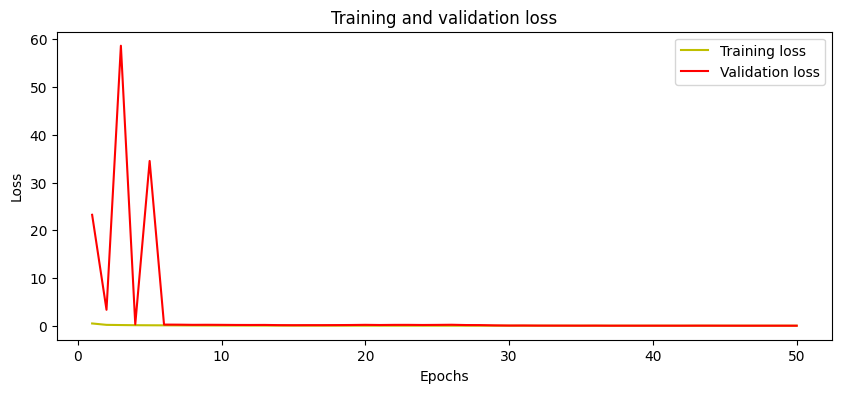

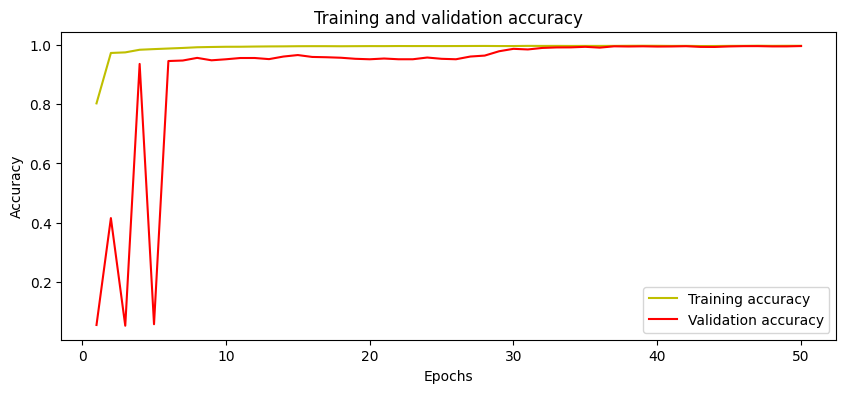

In [22]:
loss = history.history["loss"]
val_loss = history.history["val_loss"]
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
epochs_range = range(1, len(loss) + 1)

plt.figure(figsize=(10, 4))
plt.plot(epochs_range, loss, "y", label="Training loss")
plt.plot(epochs_range, val_loss, "r", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs"); plt.ylabel("Loss"); plt.legend()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(epochs_range, acc, "y", label="Training accuracy")
plt.plot(epochs_range, val_acc, "r", label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs"); plt.ylabel("Accuracy"); plt.legend()
plt.show()

## 6. Evaluation: MeanIoU on the test set

In [23]:
threshold = 0.5
y_pred_prob = model.predict(X_test, batch_size=BATCH_SIZE)
y_pred = (y_pred_prob > threshold).astype(np.uint8)
print("Prediction shape:", y_pred.shape)

iou = MeanIoU(num_classes=2)
iou.update_state(y_test, y_pred)
print("Mean IoU =", iou.result().numpy())

5/5 ━━━━━━━━━━━━━━━━━━━━ 38s 7s/step
Prediction shape: (66, 256, 256, 1)
Mean IoU = 0.9598085


In [26]:
# Per-class IoU from the confusion matrix
cm = np.array(iou.total_cm.numpy()).reshape(2, 2)
print("Confusion matrix:\n", cm)
background_iou = cm[0, 0] / (cm[0, 0] + cm[0, 1] + cm[1, 0])
mitochondria_iou = cm[1, 1] / (cm[1, 1] + cm[0, 1] + cm[1, 0])
print("IoU background  :", background_iou)
print("IoU mitochondria:", mitochondria_iou)

Confusion matrix:
 [[4107178    8574]
 [   8084  201540]]
IoU background  : 0.9959605571123585
IoU mitochondria: 0.9236564954765855


## 7. Qualitative results

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 800ms/step


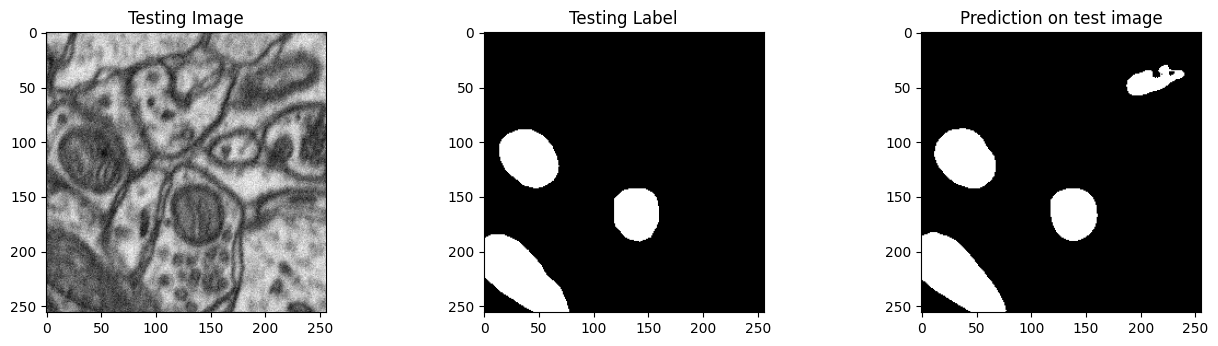

In [29]:
test_img_number = random.randint(0, len(X_test) - 1)
test_img = X_test[test_img_number]
ground_truth = y_test[test_img_number]
test_img_input = np.expand_dims(test_img, 0)
prediction = (model.predict(test_img_input)[0, :, :, 0] > threshold).astype(np.uint8)

plt.figure(figsize=(16, 8))
plt.subplot(231)
plt.title("Testing Image")
plt.imshow(test_img[:, :, 0], cmap="gray")
plt.subplot(232)
plt.title("Testing Label")
plt.imshow(ground_truth[:, :, 0], cmap="gray")
plt.subplot(233)
plt.title("Prediction on test image")
plt.imshow(prediction, cmap="gray")
plt.show()